# Import Data

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('../data/raw/Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Menghapus spasi pada kolom teks

In [3]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

C:\Users\MyBook Hype\AppData\Local\Temp\ipykernel_26780\1126013313.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


# Mengubah TotalCharges menjadi numerik

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.TotalCharges.dtypes

dtype('float64')

# Cek dan tangani Missing Values

In [6]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

dari hasil pemeriksaan terlihat bahwa fitur/variabel TotalCharges memiliki 11 missing value. Namun Penanganan Missing Value akan dilakukan ada pipeline setlah data di splitting untung mencegah adanya data leakge

# Cek dan tangani Data Duplikat

In [7]:
print('Jumlah Data duplikat:', df.duplicated().sum())

Jumlah Data duplikat: 0


Tidak ada Data duplikat

# Cek dan Tangani outlier Variabel Numerik

<function matplotlib.pyplot.show(close=None, block=None)>

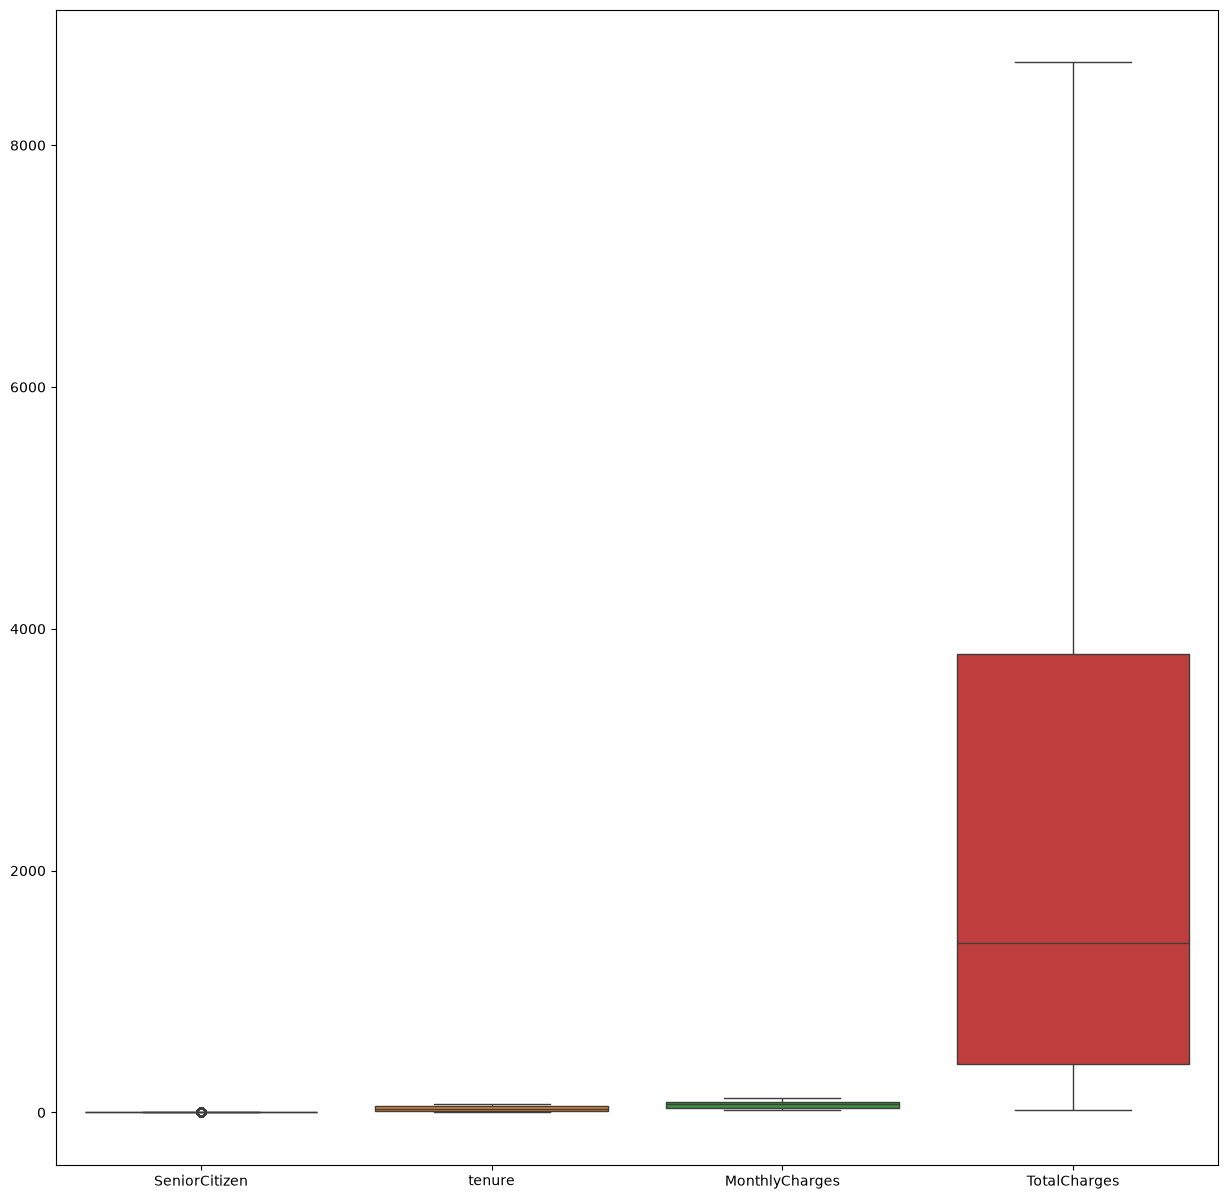

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 15))
sns.boxplot(data=df)
plt.show

Jika dilihat sekilas mata mungkin tidak terlihat ada outlier, Namun sebenarnya ada sedikit outlier pada fitur/variabel SeniorCitizen dimana terlihat ada sedikit titik/bulatan yang menonjol

## Penanganan outlier

In [9]:
def handle_outliers_iqr(df,columns):
    df_clean=df.copy()
    for col in columns:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1

        # btas atas dan bawah
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # ubah nilai
        df_clean[col]= df_clean[col].clip(lower=lower_bound, upper=upper_bound)

    return df_clean

num_cols=['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
df = handle_outliers_iqr(df, num_cols)

## Pengecekan Ulang

<function matplotlib.pyplot.show(close=None, block=None)>

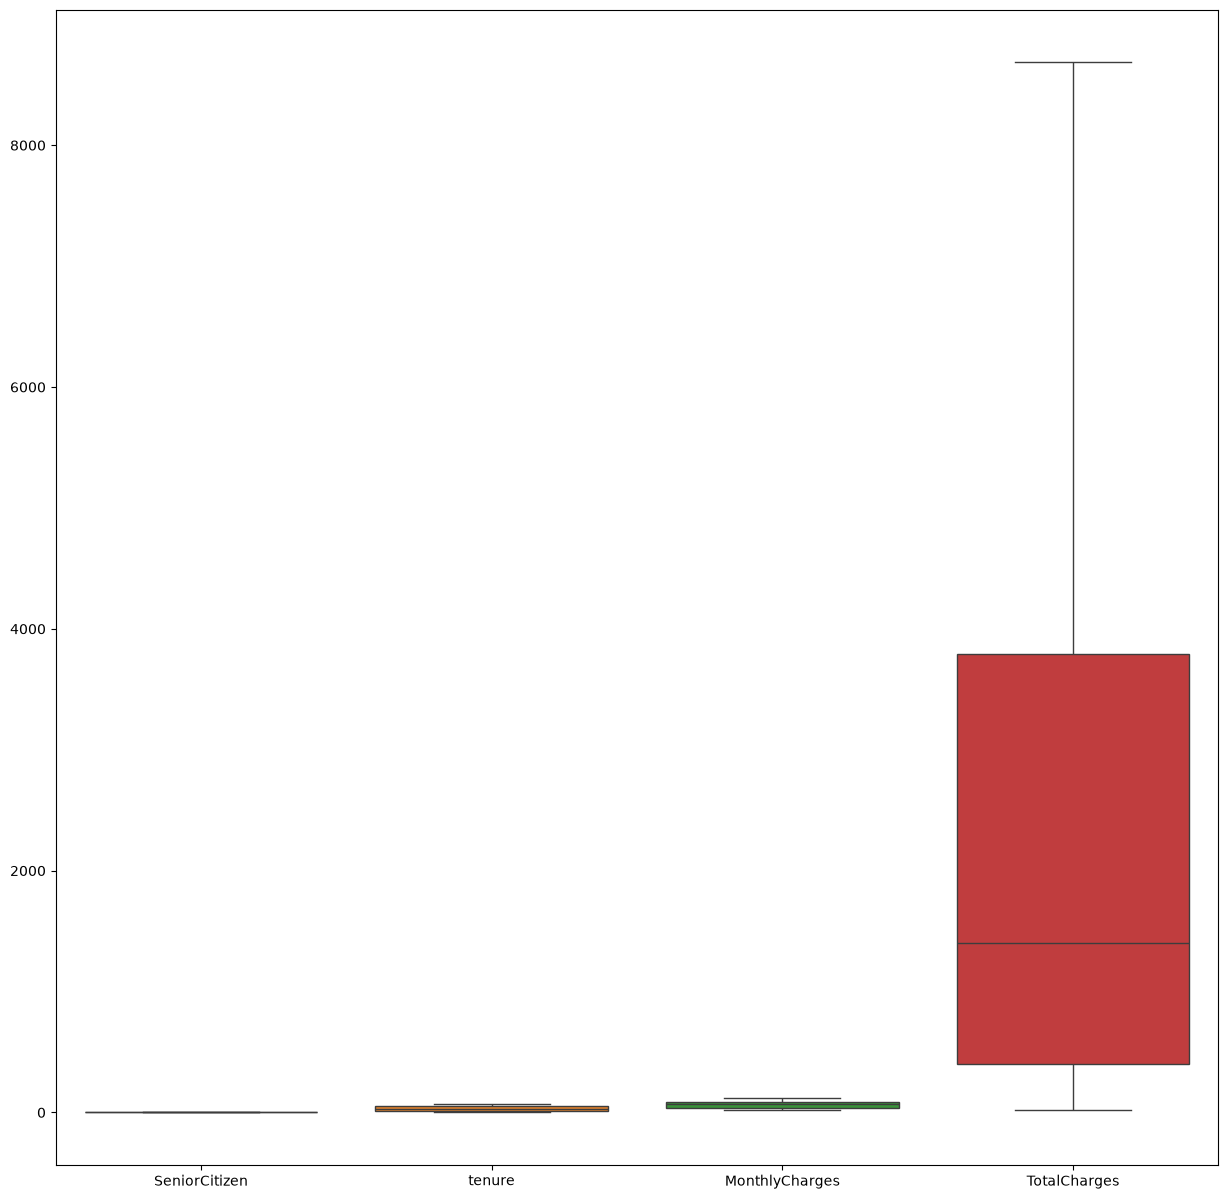

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 15))
sns.boxplot(data=df)
plt.show

# Simpan data Cleaning

In [11]:
df.to_csv("../data/processed/telco_clean.csv", index=False)

print("Data hasil cleaning berhasil disimpan.")

Data hasil cleaning berhasil disimpan.
